Todo lo que dice la web app sale de las tablas del 1_, y este pipeline las mira de a una pregunta
por vez. Primero la red: qué tan confiables son sus fechas, cuánto se parece a la del ONDaT y a los
mapas de hoy, y cómo se repartió entre pasajeros, carga, vía sin trenes y vía levantada. Después la
gente: quién tiene un tren cerca hoy, dónde vive, y cuánto de lo que cambió entre censos se debe a
la red y cuánto a la mudanza.

## Datos

Todo del 1_, en `data/pipeline`:

- `vias.parquet` — `km`, `alta`, `baja`, `dist_alta_km`, `dist_baja_km`, `activo`, `categoria` y
  `geometry` de cada parte de vía.
- `estaciones.parquet` y `estaciones_vias.csv` — `x`, `y`, `fuente`, `baja` y `cuenta` de cada
  estación, y las partes que tiene a menos de 500 m.
- `radios.parquet` — `censo`, `cod_prov`, `pob`, `area_km2`, `x`, `y`, `acceso` y `acceso_hoy` de
  cada radio.
- `provincias.parquet`, `provincias_nombres.csv` y `ondat.csv` — el mapa base, los nombres y la red
  en servicio según el ONDaT.

Para comparar a ojo van además mapas de otros, también en `data/pipeline`:
`mapa_red_ferroviaria_2021_todas_categorias.png`, `mapa_red_ferroviaria_2021_solo_activas.png` y
`red_ferroviaria_argentina.jpeg`.

In [20]:
# PyCharm elige un backend que abre ventana aparte sin esto.
%matplotlib inline

import io
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection, PatchCollection, PolyCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Circle, Patch
from matplotlib.colors import to_rgb
from scipy.spatial import cKDTree
from PIL import Image as Cuadro
from IPython.display import Image
from pathlib import Path

PIPELINE = Path('data/pipeline')

UMBRAL_KM = 10       # km, la misma regla del 1_
ANIO_MIN, ANIO_MAX = 1857, 2025
CENSOS = [1991, 2001, 2010, 2022]
CORTES = [1961, 1977, 1993]
CIERRES_DESDE = 1940   # antes, Wikidata casi no tiene fechas de cierre
GIF_DPI = 60           # puntos por pulgada de cada cuadro del gif
GIF_MS_POR_ANIO = 120  # milisegundos que dura cada año en el gif
GIF_DPI_CENSOS = 80       # puntos por pulgada de los gifs de cuatro paneles
GIF_MS_POR_CENSO = 1000   # milisegundos que dura cada censo en el gif
PERSONAS_POR_PUNTO2 = 50   # personas por punto² de área en el mapa de radios
MIN_CIRCULO = 1000         # personas: un círculo del Dorling con menos no se dibuja
R_MAX_CIRCULO = 60_000     # metros de radio del círculo con más gente de todos los censos
R_HEX = 25_000             # metros: hexágonos de 50 km de punta a punta
POB_HEX = (1e3, 3e6)       # personas: la escala logarítmica de los hexágonos va de uno a otro

VIAS = ['pasajeros', 'carga', 'inactiva', 'levantada']
PASAJEROS, CARGA = 'con tren de pasajeros', 'sólo tren de carga'
CERRADA, NUNCA = 'perdió el tren', 'nunca tuvo tren'
TIPOS = [PASAJEROS, CARGA, CERRADA, NUNCA]
# Los colores de la web app: la vía y la gente que vive cerca de ella comparten color.
COLOR_VIA = {'pasajeros': '#178a6a', 'carga': '#e69a48', 'inactiva': '#93281f', 'levantada': '#93281f'}
COLOR = {PASAJEROS: '#178a6a', CARGA: '#e69a48', CERRADA: '#93281f', NUNCA: '#9a9184'}
COLOR_ESTACION = {'pasajeros': COLOR_VIA['pasajeros'], 'carga': COLOR_VIA['carga'],
                  'cerrada': COLOR_VIA['inactiva']}
FONDO = '#fcfcfb'
COLOR_CENSO = {1991: '#1b9e77', 2001: '#d95f02', 2010: '#7570b3', 2022: '#e7298a'}
# Los de cada mapa de referencia, para que la comparación a ojo sea directa.
COLOR_EN_SERVICIO = '#2a78d6'
ESTILO_2021 = {'pasajeros': ('#6a9e1f', '-'), 'carga': ('#3ab4e8', '-'),
               'inactiva': ('#e5524c', '-'), 'levantada': ('#e5524c', ':')}

vias = gpd.read_parquet(PIPELINE / 'vias.parquet')
estaciones = pd.read_parquet(PIPELINE / 'estaciones.parquet')
estaciones_vias = pd.read_csv(PIPELINE / 'estaciones_vias.csv')
radios = pd.read_parquet(PIPELINE / 'radios.parquet')
provincias = gpd.read_parquet(PIPELINE / 'provincias.parquet')
ondat = pd.read_csv(PIPELINE / 'ondat.csv').set_index('anio').red_km

# La misma regla del 1_ para la categoría de un año.
KM = vias.km.values
ALTA = vias.alta.values
FIN_PASAJEROS = np.where(vias.categoria == 'pasajeros', np.inf, vias.baja)
FIN_SERVICIO = np.where(vias.categoria.isin(['pasajeros', 'carga']), np.inf, vias.baja)
CATEGORIA_HOY = vias.categoria.values

def categoria_en(anio):
    """La categoría de cada parte en un año, o '' si todavía no estaba construida."""
    construida = ALTA <= anio
    pasajeros = construida & (anio < FIN_PASAJEROS)
    carga = construida & ~pasajeros & (anio < FIN_SERVICIO)
    cerrada = construida & ~pasajeros & ~carga
    return np.select([pasajeros, carga, cerrada], ['pasajeros', 'carga', CATEGORIA_HOY], default='')

PAR_ESTACION = estaciones_vias.estacion.values
PAR_PARTE = estaciones_vias.parte.values

def estaciones_sobre(cat, categorias):
    """Las estaciones que tienen a menos de 500 m alguna parte de esas categorías."""
    marca = np.zeros(len(estaciones), bool)
    np.logical_or.at(marca, PAR_ESTACION, np.isin(cat[PAR_PARTE], categorias))
    return marca

def cuadro(fig, dpi=GIF_DPI):
    png = io.BytesIO()
    fig.savefig(png, format='png', dpi=dpi, facecolor='white')
    # Cada cuadro con su propia paleta, y por cobertura: por mediana, el color de una leyenda o de
    # pocas estaciones se pierde entre los tonos del borde de las líneas.
    return Cuadro.open(png).convert('RGB').quantize(256, method=Cuadro.Quantize.MAXCOVERAGE)

def gif(cuadros, ms_por_cuadro):
    datos = io.BytesIO()
    cuadros[0].save(datos, format='GIF', save_all=True, append_images=cuadros[1:], duration=ms_por_cuadro, loop=0)
    print(f'{len(cuadros)} cuadros · {datos.getbuffer().nbytes / 1e6:.1f} MB')
    return Image(data=datos.getvalue(), format='gif')

def sin_bordes(ax):
    for lado in ('top', 'right'):
        ax.spines[lado].set_visible(False)

## Qué tan confiables son las fechas

Cada parte de vía toma sus años de la estación fechada más cercana, así que la distancia hasta esa
estación dice cuánto creerle. El alta está casi siempre cerca. La baja no: muchas partes de vía sin
trenes toman el año de una estación a decenas de kilómetros.

In [21]:
for etiqueta, distancia in [('alta', vias.dist_alta_km), ('baja, en la vía no operativa', vias.dist_baja_km[~vias.activo])]:
    print(f'{etiqueta}: mediana {distancia.median():.1f} km · '
          f'{100 * (distancia < 20).mean():.0f}% de las partes a menos de 20 km de su estación')

alta: mediana 5.4 km · 65% de las partes a menos de 20 km de su estación
baja, en la vía no operativa: mediana 24.6 km · 46% de las partes a menos de 20 km de su estación


## Control contra el ONDaT

El ONDaT mide la red en servicio, no la construida, así que se compara con la vía con pasajeros más
la de carga. Su serie termina en 2000 y no tiene 1934 ni 1936. Desde 1993 queda un 17% por
debajo, probablemente porque la vía que hoy no tiene trenes sale de servicio el año en que cerró su
estación más cercana, aunque parte siguió con carga unos años más.

1857–1919: en servicio / ONDaT, mediana 1.86
1920–1949: en servicio / ONDaT, mediana 1.10
1950–1992: en servicio / ONDaT, mediana 1.01
1993–2000: en servicio / ONDaT, mediana 0.83


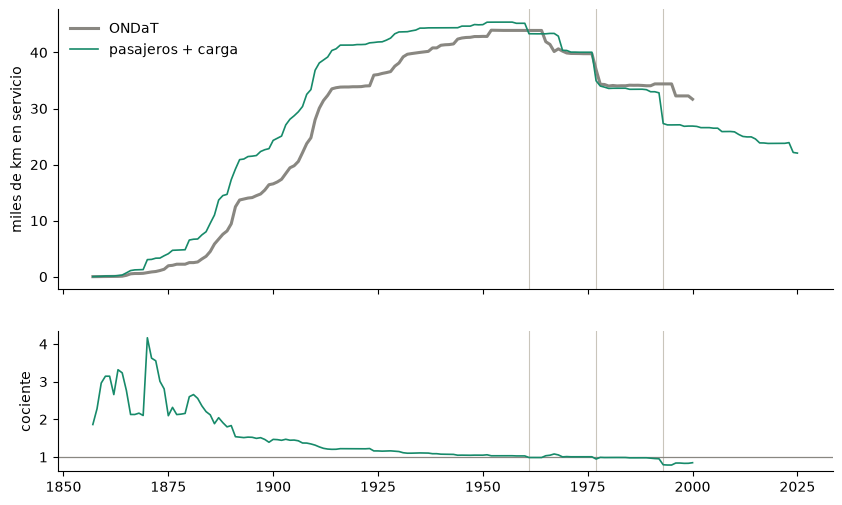

In [22]:
anios = np.arange(ANIO_MIN, ANIO_MAX + 1)
km = pd.DataFrame(0.0, index=anios, columns=VIAS)
for anio in anios:
    cat = categoria_en(anio)
    for c in VIAS:
        km.loc[anio, c] = KM[cat == c].sum()
en_servicio = km.pasajeros + km.carga
cociente = (en_servicio / ondat.reindex(anios)).dropna()
for desde, hasta in [(1857, 1919), (1920, 1949), (1950, 1992), (1993, 2000)]:
    print(f'{desde}–{hasta}: en servicio / ONDaT, mediana {cociente.loc[desde:hasta].median():.2f}')

fig, (arriba, abajo) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
arriba.plot(ondat.index, ondat / 1000, color='#898781', lw=2.2, label='ONDaT')
arriba.plot(anios, en_servicio / 1000, color=COLOR_VIA['pasajeros'], lw=1.2, label='pasajeros + carga')
arriba.set_ylabel('miles de km en servicio')
arriba.legend(frameon=False)
abajo.axhline(1, color='#898781', lw=.9)
abajo.plot(cociente.index, cociente.values, color=COLOR_VIA['pasajeros'], lw=1.2)
abajo.set_ylabel('cociente')
for ax in (arriba, abajo):
    for corte in CORTES:
        ax.axvline(corte, color='#c9c5bb', lw=.8, zorder=0)
    sin_bordes(ax)
plt.show()

## La red de un año

`mapa(anio)` dibuja la red de ese año en sus cuatro categorías, con la vía levantada punteada.

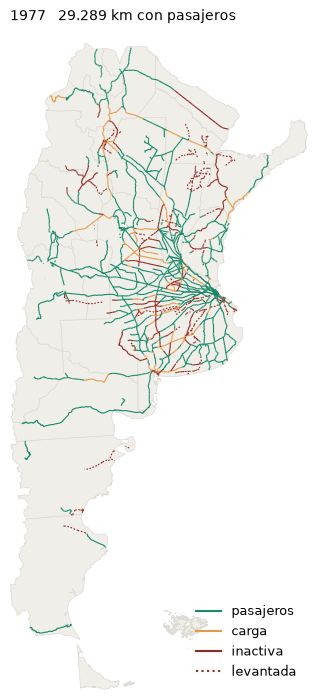

In [23]:
SEGMENTOS = [np.asarray(g.coords) for g in vias.geometry]

# Una sola figura reusada: crear una por llamada las apila en PyCharm.
FIG, AX = plt.subplots(figsize=(5.6, 8.4))
provincias.plot(ax=AX, color='#f0eee9', edgecolor='#dedbd2', linewidth=.5)
LINEAS = LineCollection(SEGMENTOS, linewidths=.8)
PUNTEADAS = LineCollection(SEGMENTOS, linewidths=.8, linestyles=(0, (1.5, 1.5)))
AX.add_collection(PUNTEADAS)
AX.add_collection(LINEAS)
AX.set_aspect('equal', adjustable='box')
AX.set_xlim(provincias.total_bounds[0], provincias.total_bounds[2])
AX.set_ylim(provincias.total_bounds[1], provincias.total_bounds[3])
AX.set_axis_off()
AX.legend(handles=[Line2D([], [], color=COLOR_VIA[c], ls=':' if c == 'levantada' else '-', label=c)
                   for c in VIAS], loc='lower right', frameon=False, fontsize=9)
plt.close(FIG)   # que no se dibuje sola al ejecutar la celda

def mapa(anio=1977):
    cat = categoria_en(anio)
    colores = [COLOR_VIA[c] if c else 'none' for c in cat]
    LINEAS.set_color(np.where(cat == 'levantada', 'none', colores))
    PUNTEADAS.set_color(np.where(cat == 'levantada', colores, 'none'))
    km_pasajeros = f'{KM[cat == "pasajeros"].sum():,.0f}'.replace(',', '.')
    AX.set_title(f'{anio}   {km_pasajeros} km con pasajeros', fontsize=10, loc='left')
    return FIG   # devolverla funciona igual en Jupyter y en PyCharm

mapa(1977)

## La red año por año

El mapa de cada año, de 1857 a 2025, en un gif que se ve dentro del notebook sin kernel ni widgets.

169 cuadros · 2.0 MB


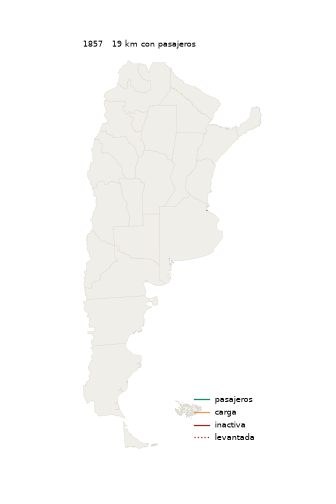

In [24]:
cuadros = []
for anio in range(ANIO_MIN, ANIO_MAX + 1):
    cuadros.append(cuadro(mapa(anio)))
gif(cuadros, GIF_MS_POR_ANIO)

## Las estaciones año por año

La misma red, dibujada sólo con sus estaciones. Cada estación que cuenta toma la mejor categoría de
las partes que tiene a menos de 500 m, la regla del 1_. Aparece cuando se construye la primera de
esas partes y queda como cerrada cuando ninguna lleva trenes.

169 cuadros · 2.0 MB


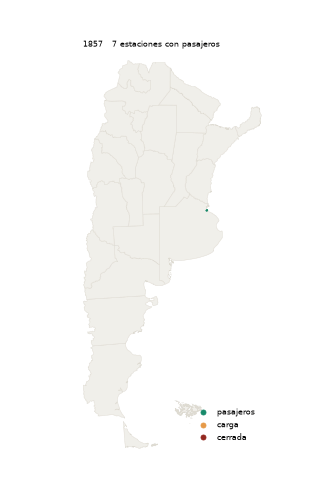

In [25]:
def categoria_estacion(anio):
    """La categoría de cada estación en un año, o '' si todavía no tenía vía."""
    cat = categoria_en(anio)
    return np.select([estaciones_sobre(cat, ['pasajeros']), estaciones_sobre(cat, ['carga']), estaciones_sobre(cat, VIAS)],
                     ['pasajeros', 'carga', 'cerrada'], default='')

FIG_EST, AX_EST = plt.subplots(figsize=(5.6, 8.4))
provincias.plot(ax=AX_EST, color='#f0eee9', edgecolor='#dedbd2', linewidth=.5)
PUNTOS = AX_EST.scatter(estaciones.x, estaciones.y, s=4, linewidths=0)
AX_EST.set_aspect('equal', adjustable='box')
AX_EST.set_xlim(provincias.total_bounds[0], provincias.total_bounds[2])
AX_EST.set_ylim(provincias.total_bounds[1], provincias.total_bounds[3])
AX_EST.set_axis_off()
AX_EST.legend(handles=[Line2D([], [], color=COLOR_ESTACION[c], marker='o', ls='', label=c) for c in COLOR_ESTACION],
              loc='lower right', frameon=False, fontsize=9)
plt.close(FIG_EST)

def mapa_estaciones(anio=1977):
    cat = categoria_estacion(anio)
    colores = []
    for c in cat:
        colores.append(COLOR_ESTACION[c] if c else 'none')
    PUNTOS.set_color(colores)
    con_pasajeros = f'{(cat == "pasajeros").sum():,}'.replace(',', '.')
    AX_EST.set_title(f'{anio}   {con_pasajeros} estaciones con pasajeros', fontsize=10, loc='left')
    return FIG_EST

cuadros = []
for anio in range(ANIO_MIN, ANIO_MAX + 1):
    cuadros.append(cuadro(mapa_estaciones(anio)))
gif(cuadros, GIF_MS_POR_ANIO)

## La red de hoy contra otros mapas

Dos comparaciones a ojo con mapas de otros, cada una dibujada con los colores de su referencia.
No son fuentes oficiales, pero son las visualizaciones más claras y recientes que hay.

### La vía en servicio y los corredores de 2026

La vía con pasajeros o con carga de 2025, en un solo color, al lado de un mapa de corredores
operativos de 2026 ([fuente](https://x.com/GGertino/status/1940247940452536692)). Sirve para ver
qué vía está en uso, sin mirar qué lleva.

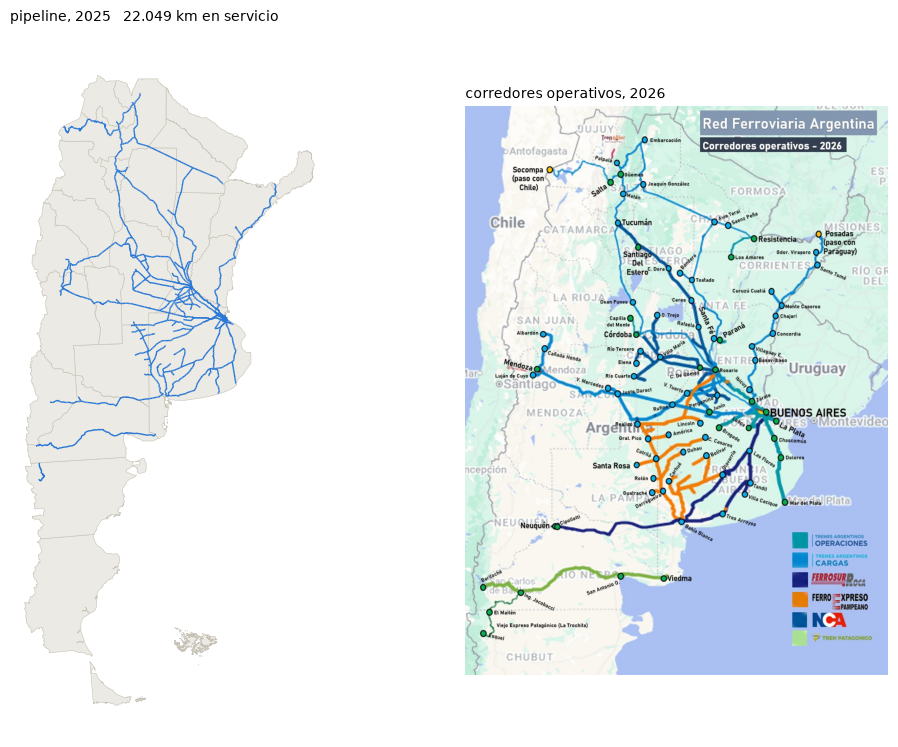

In [26]:
en_servicio = vias[vias.categoria.isin(['pasajeros', 'carga'])]
km_en_servicio = f'{en_servicio.km.sum():,.0f}'.replace(',', '.')

fig, (ax, ax_ref) = plt.subplots(1, 2, figsize=(12, 9))
provincias.plot(ax=ax, color='#eceae4', edgecolor='#c6c2b6', linewidth=.4)
en_servicio.plot(ax=ax, color=COLOR_EN_SERVICIO, linewidth=1)
ax.set_title(f'pipeline, {ANIO_MAX}   {km_en_servicio} km en servicio', fontsize=10, loc='left')
ax_ref.imshow(plt.imread(PIPELINE / 'red_ferroviaria_argentina.jpeg'))
ax_ref.set_title('corredores operativos, 2026', fontsize=10, loc='left')
for a in (ax, ax_ref):
    a.set_axis_off()
plt.show()

### La red categorizada y el mapa de 2021

Las cuatro categorías de 2025 al lado de un mapa de 2021 que usa las mismas
([fuente](https://www.reddit.com/r/argentina/comments/mbkvuu/mapa_de_la_red_ferroviaria_de_argentina_2021/)),
primero con toda la vía y después sólo con la que está en uso.

La diferencia con el de 2021 está casi toda en la vía de pasajeros: desde entonces dejaron de correr
varios servicios, y esa vía hoy aparece como de carga. El Constitución – Bahía Blanca dejó de
circular en marzo de 2023 y en julio de 2025 se cerró la estación Bahía Blanca Sud
([Canal 26](https://www.canal26.com/general/2025/10/19/por-que-suspendieron-el-historico-tren-buenos-aires-bahia-blanca-que-conectaba-a-la-ciudad-con-el-punto-mas-austral-de-la-provincia/)),
y el Bragado – Pehuajó se suspendió en noviembre de 2024
([MDZ](https://www.mdzol.com/sociedad/2024/10/22/trenes-argentinos-cual-es-el-ramal-ferroviario-que-dejara-de-funcionar-en-poco-tiempo-1161030.html)).
Los trenes de Buenos Aires a Tucumán, Córdoba, Villa María y Justo Daract, que pasaba por Rufino,
están sin servicio desde 2025
([Canal 26](https://www.canal26.com/general/2025/10/27/trenes-argentinos-extendio-la-suspension-de-un-importante-servicio-de-larga-distancia-los-motivos/),
[El Cronista](https://www.cronista.com/informacion-gral/otros-dos-trenes-de-larga-distancia-dejan-de-funcionar-cuales-son-y-por-que/)),
y el de Pinamar sigue suspendido
([El Destape](https://www.eldestapeweb.com/economia/cuanto-sale-boleto-tren-junio-2026-tarifas-recorridos-cortos-larga-distancia-202661295757)).
En Entre Ríos el último servicio, Paraná – La Picada, está suspendido desde mayo de 2026
([Análisis Digital](https://www.analisisdigital.com.ar/locales/2026/05/18/el-servicio-de-tren-continua-suspendido-pero-aumento-su-tarifa)).
En sentido contrario, hoy corren el Tren Patagónico entre Viedma y Bariloche y los trenes de
Córdoba a La Calera y a Valle Hermoso.

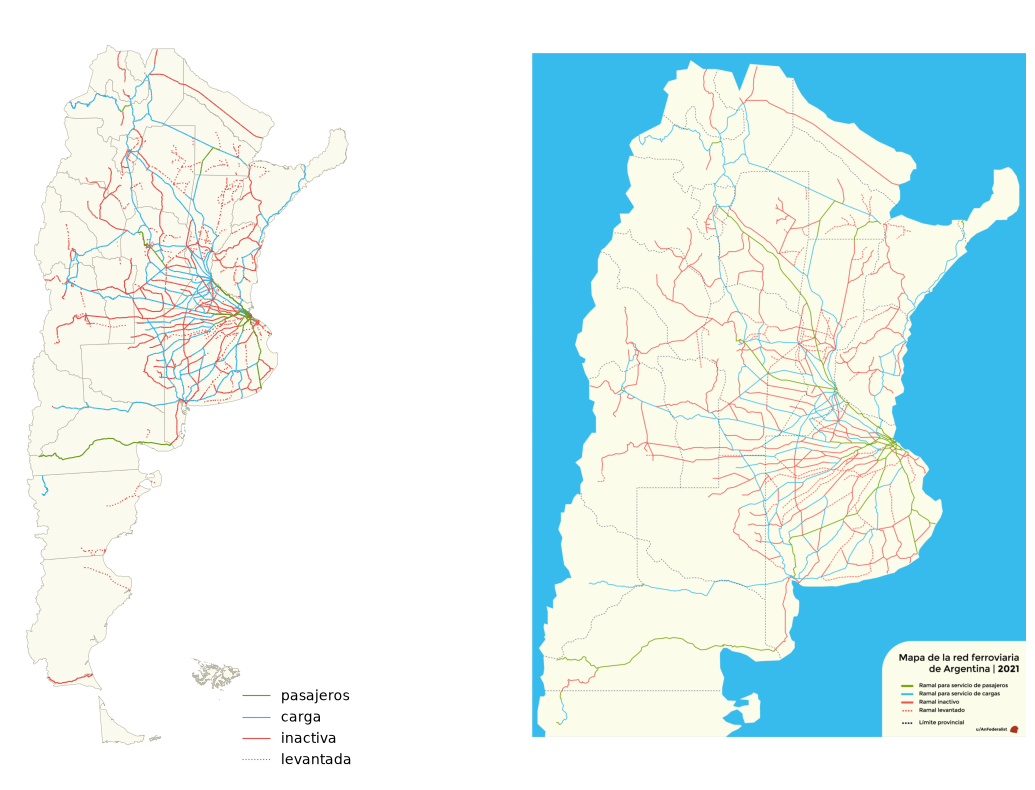

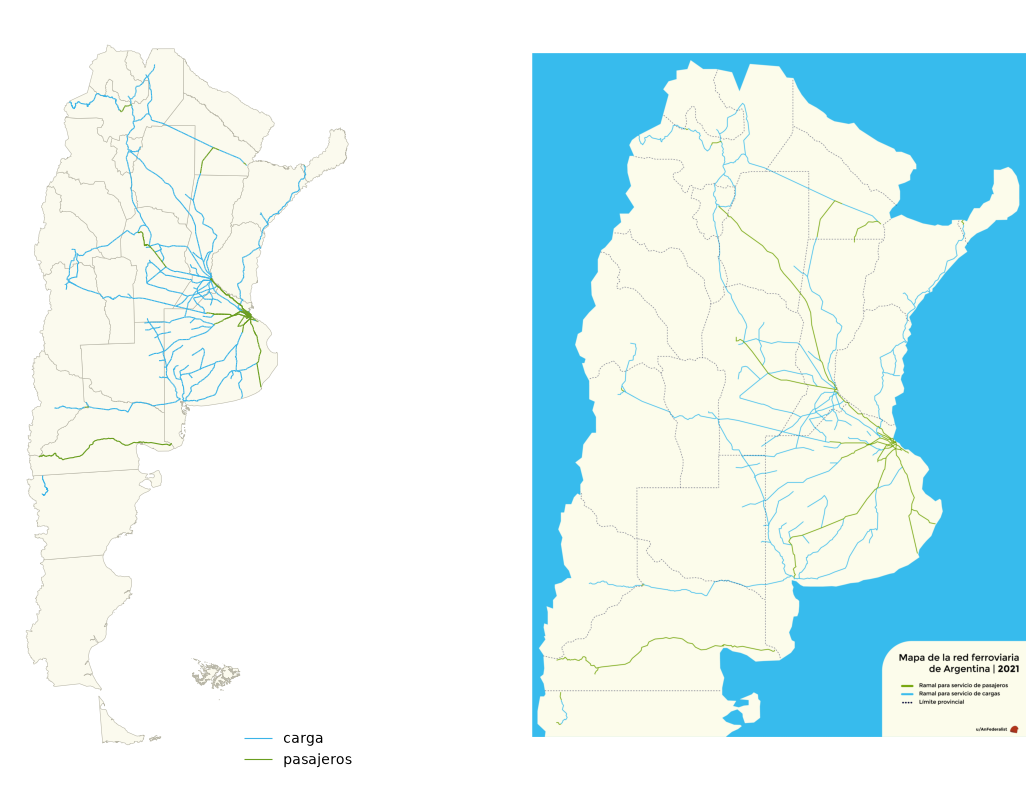

In [27]:
REFERENCIAS_2021 = [(VIAS, 'mapa_red_ferroviaria_2021_todas_categorias.png'),
                    (['carga', 'pasajeros'], 'mapa_red_ferroviaria_2021_solo_activas.png')]
for categorias, referencia in REFERENCIAS_2021:
    fig, (ax, ax_ref) = plt.subplots(1, 2, figsize=(14, 10))
    provincias.plot(ax=ax, color='#fbfaee', edgecolor='#b9b7a8', linewidth=.4)
    for c in categorias:
        color, linea = ESTILO_2021[c]
        vias[vias.categoria == c].plot(ax=ax, color=color, linestyle=linea, linewidth=.8, label=c)
    ax.legend(loc='lower right', frameon=False)
    ax_ref.imshow(plt.imread(PIPELINE / referencia))
    for a in (ax, ax_ref):
        a.set_axis_off()
    plt.show()

## Cuándo cerraron las estaciones

Las estaciones de Wikidata con año de cierre entre 1940 y 2025, una vez cada una, tengan o no
coordenadas. Tres años sobresalen de todo el resto: 1961, el del Plan Larkin; 1977, el del cierre
más grande; y 1993, el del fin de la larga distancia. Sólo una parte de las estaciones tiene fecha
de cierre, así que las barras son un piso y no el total.

706 estaciones con año de cierre · 53% en [1961, 1977, 1993]


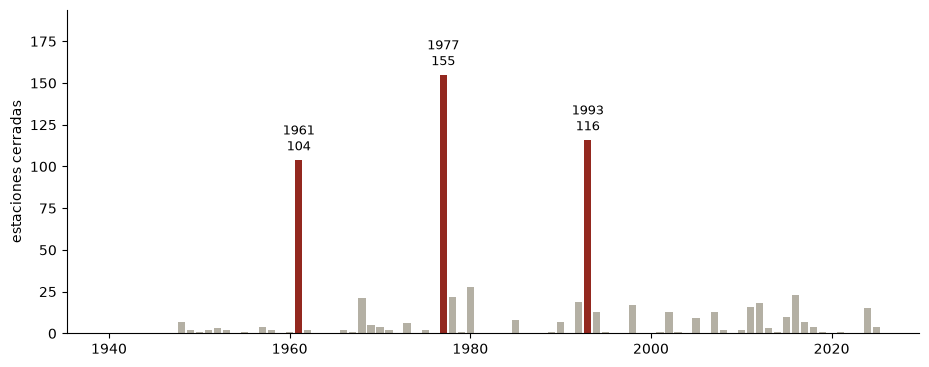

In [28]:
cierre = estaciones.baja[(estaciones.fuente == 'Wikidata') & estaciones.baja.between(CIERRES_DESDE, ANIO_MAX)]
por_anio = cierre.astype(int).value_counts().reindex(range(CIERRES_DESDE, ANIO_MAX + 1), fill_value=0)
print(f'{len(cierre)} estaciones con año de cierre · {100 * por_anio[CORTES].sum() / len(cierre):.0f}% en {CORTES}')

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(por_anio.index, por_anio.values, width=.8,
       color=[COLOR_VIA['inactiva'] if a in CORTES else '#b4b0a4' for a in por_anio.index])
for a in CORTES:
    ax.text(a, por_anio[a] + 3, f'{a}\n{por_anio[a]}', ha='center', va='bottom', fontsize=9.5)
ax.set_ylim(0, por_anio.max() * 1.25)
ax.set_ylabel('estaciones cerradas')
sin_bordes(ax)
plt.show()

## Los km de cada categoría

La vía construida hasta cada año, apilada por categoría. La vía cerrada se acumula, porque no se
descuenta cuando se levanta. Es la serie del gráfico de la web app; los porcentajes de hoy son los
del texto de Actualidad.

máximo con pasajeros: 45.203 km en 1955
hoy, de cada 100 km construidos: {'pasajeros': 10, 'carga': 38, 'inactiva': 30, 'levantada': 22}


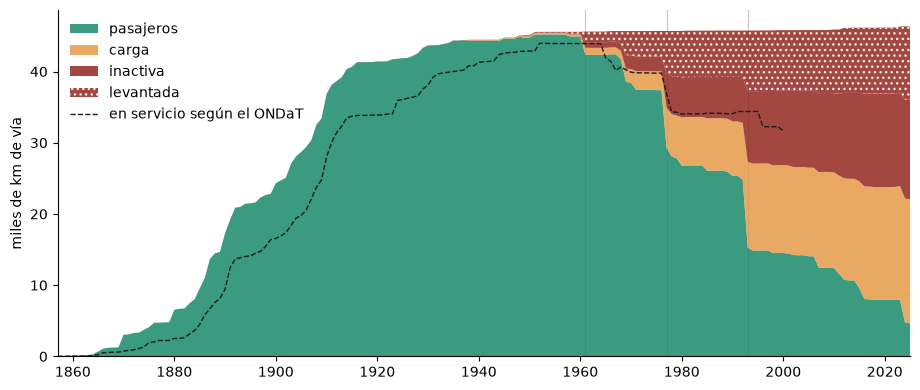

In [29]:
hoy = km.loc[ANIO_MAX]
pico = km.pasajeros.idxmax()
print(f'máximo con pasajeros: {km.pasajeros[pico]:,.0f} km en {pico}'.replace(',', '.'))
print('hoy, de cada 100 km construidos:', (100 * hoy / hoy.sum()).round().astype(int).to_dict())

fig, ax = plt.subplots(figsize=(11, 4.5))
areas = ax.stackplot(km.index, km[VIAS].T.values / 1000, colors=[COLOR_VIA[c] for c in VIAS], labels=VIAS,
                     alpha=.85, linewidth=0)
areas[VIAS.index('levantada')].set(hatch='...', edgecolor='white')
ax.plot(ondat.index, ondat / 1000, color='#1b1b1b', lw=1, ls='--', label='en servicio según el ONDaT')
for corte in CORTES:
    ax.axvline(corte, color='#c9c5bb', lw=.8, zorder=0)
ax.set_xlim(ANIO_MIN, ANIO_MAX)
ax.set_ylabel('miles de km de vía')
ax.legend(loc='upper left', frameon=False)
sin_bordes(ax)
plt.show()

## Los radios censales

El dato de partida, antes de cualquier categoría: un punto por radio censal de 2022, con el área
proporcional a su población.

66501 radios · mediana 680 personas · máximo 6.992


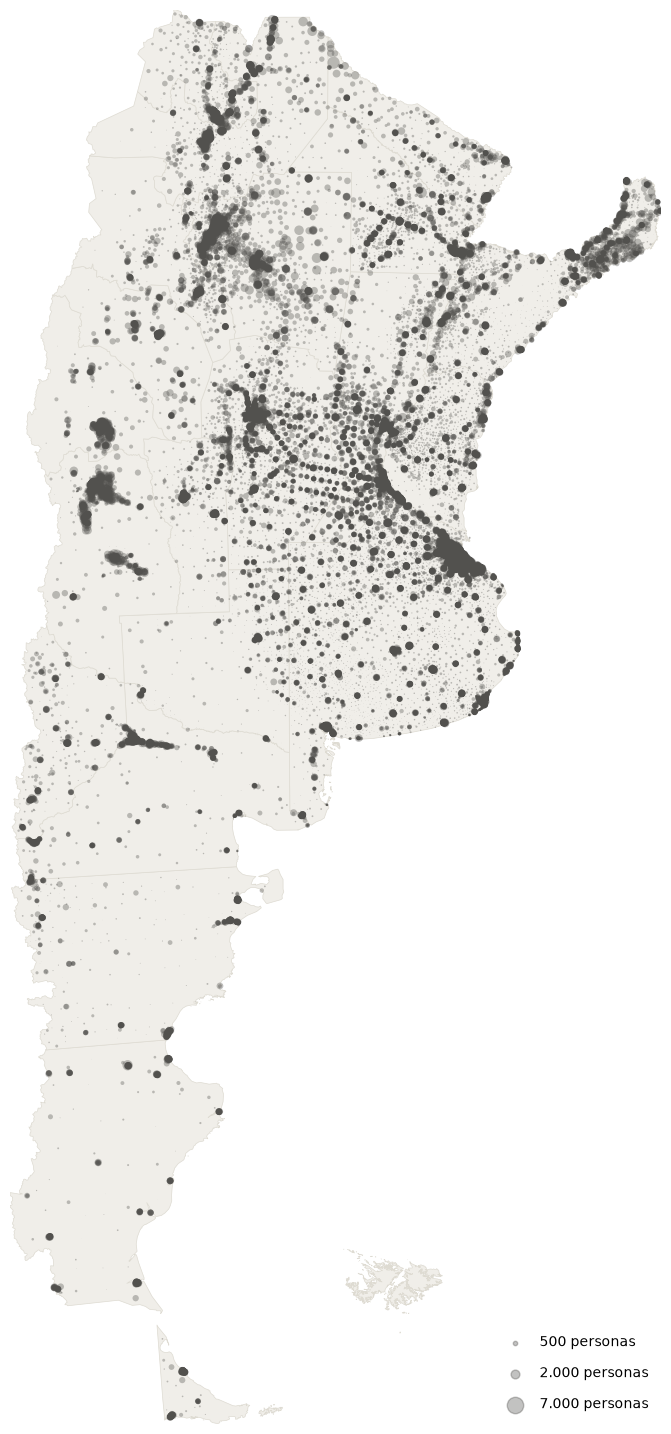

In [30]:
r22 = radios[radios.censo == 2022].copy()
print(f'{len(r22)} radios · mediana {r22.pob.median():,.0f} personas · máximo {r22.pob.max():,.0f}'.replace(',', '.'))

x0, y0, x1, y1 = provincias.total_bounds
fig, ax = plt.subplots(figsize=(7, 7 * (y1 - y0) / (x1 - x0)))
fig.subplots_adjust(left=0, right=1, bottom=.04, top=.97)
provincias.plot(ax=ax, color='#f0eee9', edgecolor='#dedbd2', linewidth=.5, zorder=0)
ax.scatter(r22.x, r22.y, s=r22.pob / PERSONAS_POR_PUNTO2, color='#52514e', alpha=.35, linewidths=0)
for personas in (500, 2_000, 7_000):
    etiqueta = f'{personas:,} personas'.replace(',', '.')
    ax.scatter([], [], s=personas / PERSONAS_POR_PUNTO2, color='#52514e', alpha=.35, label=etiqueta)
ax.legend(loc='lower right', frameon=False, labelspacing=1.2)
ax.set_xlim(x0, x1)
ax.set_ylim(y0, y1)
ax.set_aspect('equal')
ax.set_axis_off()
plt.show()

## Quién tiene un tren cerca hoy

La gente del censo 2022, el más reciente, con la red de hoy: es el punto de partida de Reconectar.

45.62 M personas
acceso_hoy
con tren de pasajeros    23.58
sólo tren de carga       10.24
perdió el tren            7.14
nunca tuvo tren           4.65


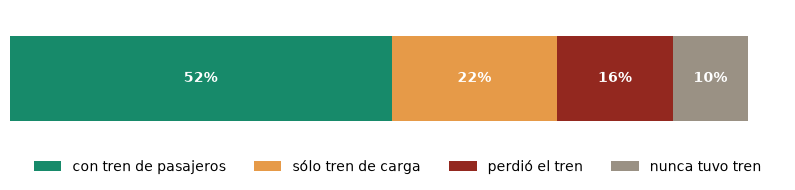

In [31]:
TOTAL = r22.pob.sum()
por_cat = r22.groupby('acceso_hoy').pob.sum().reindex(TIPOS)
print(f'{TOTAL / 1e6:.2f} M personas')
print((por_cat / 1e6).round(2).to_string())

pct = (100 * por_cat / TOTAL).to_frame().T
ax = pct.plot.barh(stacked=True, color=[COLOR[t] for t in TIPOS], width=.8, figsize=(10, 1.8))
for barras in ax.containers:
    ax.bar_label(barras, fmt='%.0f%%', label_type='center', color='white', fontweight='bold')
ax.set_axis_off()
ax.legend(loc='upper center', bbox_to_anchor=(.5, 0), ncol=4, frameon=False)
plt.show()

## Cada provincia

La misma partición, provincia por provincia, ordenada por la parte con tren de pasajeros. En la web
app va con la red de 2022, la del censo; acá con la de hoy, que es la que ve Reconectar.

acceso_hoy        con tren de pasajeros  sólo tren de carga  perdió el tren  nunca tuvo tren
cod_prov                                                                                    
Formosa                             0.0                 0.0            59.9             40.1
Santa Cruz                          0.0                 0.0            60.2             39.8
Tierra del Fuego                    0.0                 0.0             0.0            100.0
La Rioja                            0.0                 4.9            77.8             17.3
Catamarca                           0.0                 5.0            67.7             27.3
Chubut                              0.0                 7.0            81.3             11.7
Corrientes                          0.0                19.3            55.5             25.2
San Luis                            0.0                27.1            53.4             19.6
San Juan                            0.0                31.2           

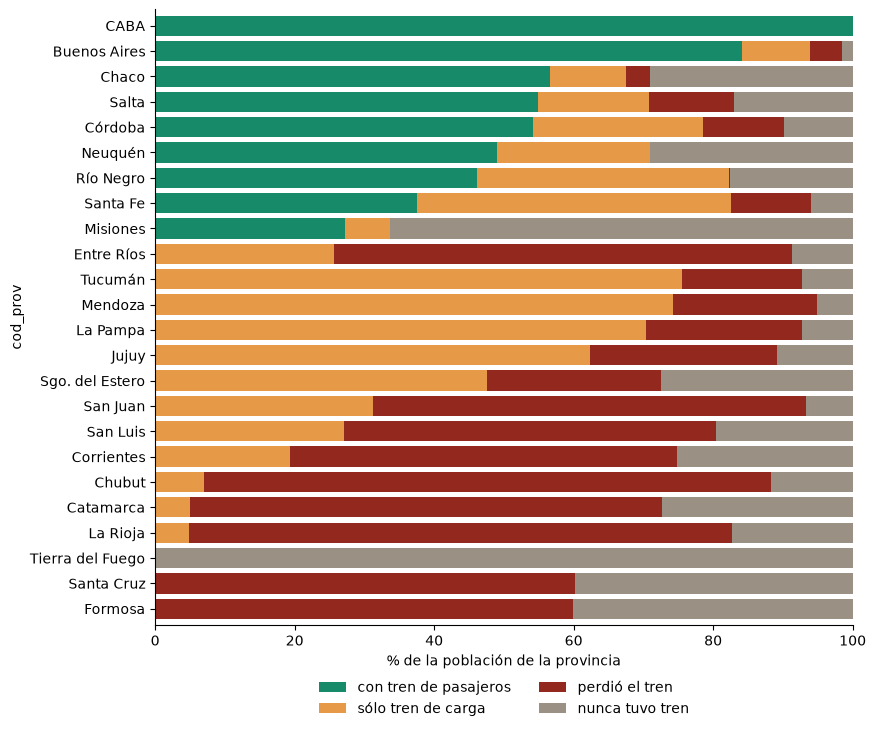

In [32]:
nombres = pd.read_csv(PIPELINE / 'provincias_nombres.csv', dtype={'cod_prov': str}).set_index('cod_prov').nombre
pob_prov = r22.pivot_table(index='cod_prov', columns='acceso_hoy', values='pob', aggfunc='sum',
                           fill_value=0).reindex(columns=TIPOS, fill_value=0)
pob_prov.index = pob_prov.index.map(nombres)
pct_prov = 100 * pob_prov.div(pob_prov.sum(axis=1), axis=0)
pct_prov = pct_prov.sort_values([PASAJEROS, CARGA])
print(pct_prov.round(1).to_string())

ax = pct_prov.plot.barh(stacked=True, color=[COLOR[t] for t in TIPOS], width=.8, figsize=(9, 8), legend=False)
ax.set_xlabel('% de la población de la provincia')
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.07), ncol=2, frameon=False)
sin_bordes(ax)
plt.show()

## Dónde vive cada categoría

Ordeno a la gente por la densidad del radio donde vive y la parto en diez deciles: cada uno es el
10% de los argentinos. Cada línea dice qué parte de una categoría vive en cada decil, así que una
categoría repartida parejo daría una línea plana en 10%. La gente sin ningún tren cerca se amontona
en los radios más rurales; la que perdió el tren o sólo tiene carga, en los pueblos y ciudades
chicas del medio.

acceso_hoy  con tren de pasajeros  sólo tren de carga  perdió el tren  nunca tuvo tren  hasta_hab_km2
decil                                                                                                
1                             2.9                10.8            13.1             39.5          651.0
2                             5.1                12.6            15.5             20.8         1865.0
3                             5.7                13.6            15.2             15.8         3059.0
4                             6.9                14.9            13.5              9.9         4310.0
5                             8.5                13.8            12.1              6.0         5602.0
6                            10.6                11.5            10.5              2.9         6962.0
7                            12.4                 9.1             8.4              2.0         8530.0
8                            14.3                 6.8             6.0             

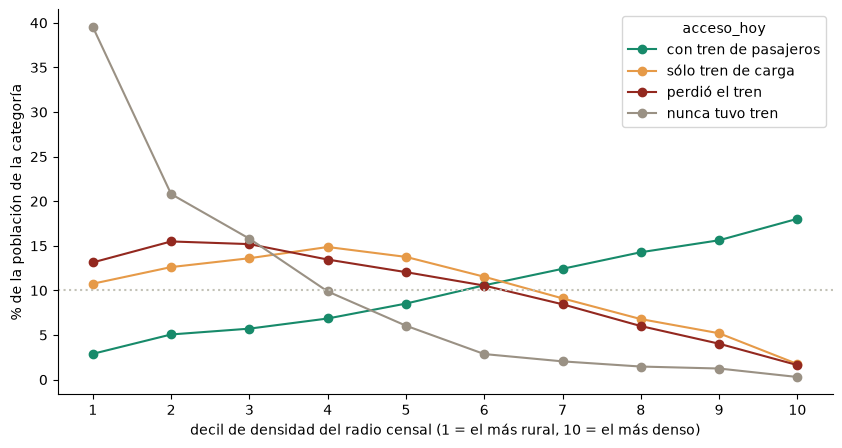

In [33]:
r22['densidad'] = r22.pob / r22.area_km2
orden = r22.sort_values('densidad')
acumulada = orden.pob.cumsum() / orden.pob.sum()
orden['decil'] = np.clip((acumulada * 10).astype(int), 0, 9) + 1
por_decil = orden.pivot_table(index='decil', columns='acceso_hoy', values='pob', aggfunc='sum',
                              fill_value=0).reindex(columns=TIPOS, fill_value=0)
pct_decil = 100 * por_decil / por_decil.sum()
pct_decil['hasta_hab_km2'] = orden.groupby('decil').densidad.max().round()
print(pct_decil.round(1).to_string())

ax = pct_decil[TIPOS].plot(color=[COLOR[t] for t in TIPOS], marker='o', figsize=(10, 5))
ax.axhline(10, color='#c3c2b7', ls=':')
ax.set_xticks(range(1, 11))
ax.set_xlabel('decil de densidad del radio censal (1 = el más rural, 10 = el más denso)')
ax.set_ylabel('% de la población de la categoría')
sin_bordes(ax)
plt.show()

## Cada censo con la red de su año

Las barras del gráfico de La gente en la web app: cada censo con la red de su año.

acceso  con tren de pasajeros  sólo tren de carga  perdió el tren  nunca tuvo tren
censo                                                                             
1991                     75.7                 7.2             6.6             10.4
2001                     60.9                15.7            12.8             10.6
2010                     58.1                17.9            13.6             10.4
2022                     54.2                20.4            15.1             10.3


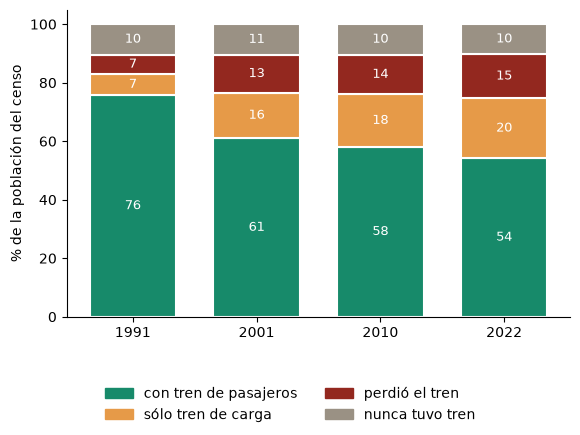

In [34]:
pct = radios.pivot_table(index='censo', columns='acceso', values='pob', aggfunc='sum').reindex(columns=TIPOS)
pct = 100 * pct.div(pct.sum(axis=1), axis=0)
print(pct.round(1).to_string())

fig, ax = plt.subplots(figsize=(6.5, 4.8))
abajo = np.zeros(len(CENSOS))
x = np.arange(len(CENSOS))
for tipo in TIPOS:
    ax.bar(x, pct[tipo], bottom=abajo, color=COLOR[tipo], width=.7, edgecolor='white', linewidth=1.5)
    for xi, b, v in zip(x, abajo, pct[tipo]):
        if v >= 5:
            ax.text(xi, b + v / 2, f'{v:.0f}', ha='center', va='center', color='white', fontsize=9)
    abajo += pct[tipo].values
ax.set_xticks(x, CENSOS)
ax.set_ylabel('% de la población del censo')
sin_bordes(ax)
fig.legend(handles=[Patch(color=COLOR[t], label=t) for t in TIPOS], loc='lower center', ncol=2, frameon=False)
fig.subplots_adjust(bottom=.24)
plt.show()

## Fijar la poblacion y ver como varia con las vias historicas

Cada curva es la gente de un censo, con la red de cada año. Las. La regla es la del 1_, con las
estaciones que cuentan y las partes que tienen a menos de 500 m.

gente de 1991: 89.3% con la red de 1960, 53.8% con la de 2025
gente de 2001: 89.1% con la red de 1960, 52.4% con la de 2025
gente de 2010: 89.2% con la red de 1960, 52.8% con la de 2025
gente de 2022: 88.9% con la red de 1960, 51.7% con la de 2025


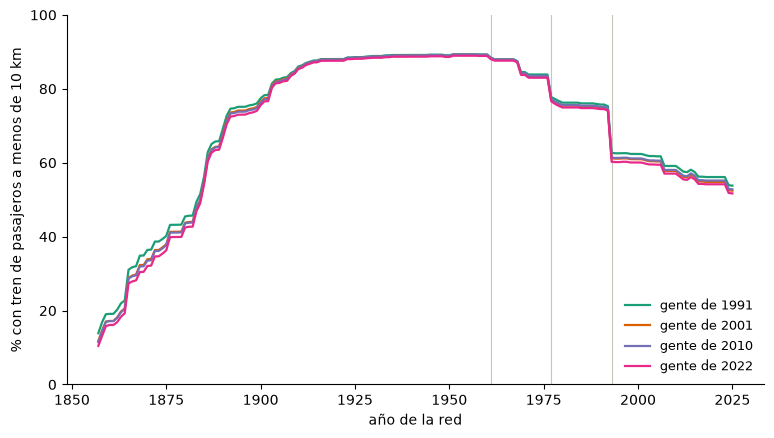

In [35]:
EST_XY = estaciones[['x', 'y']].values

def con_pasajeros(xy, anio):
    """Si cada punto tiene a menos de UMBRAL_KM una estación sobre vía con pasajeros ese año."""
    marca = estaciones_sobre(categoria_en(anio), ['pasajeros'])
    d = cKDTree(EST_XY[marca]).query(xy, distance_upper_bound=UMBRAL_KM * 1000)[0]
    return d < np.inf

fig, ax = plt.subplots(figsize=(9, 4.8))
for censo in CENSOS:
    r = radios[radios.censo == censo]
    xy = r[['x', 'y']].values
    pct = pd.Series([100 * r.pob[con_pasajeros(xy, anio)].sum() / r.pob.sum() for anio in anios], index=anios)
    ax.plot(pct.index, pct.values, color=COLOR_CENSO[censo], lw=1.6, label=f'gente de {censo}')
    print(f'gente de {censo}: {pct[1960]:.1f}% con la red de 1960, {pct[ANIO_MAX]:.1f}% con la de {ANIO_MAX}')
for corte in CORTES:
    ax.axvline(corte, color='#c9c5bb', lw=.8, zorder=0)
ax.set_xlabel('año de la red')
ax.set_ylabel('% con tren de pasajeros a menos de 10 km')
ax.set_ylim(0, 100)
ax.legend(frameon=False, fontsize=9, loc='lower right')
sin_bordes(ax)
plt.show()

## Las cuatro categorías en el mapa, censo por censo

Cada censo con la red de su año, como en el gráfico de barras de más arriba, pero en el mapa y con
un panel por categoría. Los tres gifs dan un segundo a cada censo y usan una sola escala para
todos los paneles y censos: el mismo tamaño o el mismo color es la misma cantidad de gente en
cualquier cuadro.

In [36]:
X0, Y0, X1, Y1 = provincias.total_bounds

def paneles(censo):
    """Una figura con un mapa vacío por categoría, para un cuadro de los gifs por censo."""
    fig, axs = plt.subplots(1, 4, figsize=(14, 4 * (Y1 - Y0) / (X1 - X0) + .6))
    fig.subplots_adjust(left=0, right=1, bottom=0, top=.92, wspace=.02)
    for ax, tipo in zip(axs, TIPOS):
        provincias.plot(ax=ax, color='#f0eee9', edgecolor='#dedbd2', linewidth=.4, zorder=0)
        ax.set_xlim(X0, X1)
        ax.set_ylim(Y0, Y1)
        ax.set_aspect('equal')
        ax.set_axis_off()
        ax.set_title(tipo, fontsize=11, loc='left', color=COLOR[tipo])
    fig.suptitle(str(censo), x=.01, ha='left', fontsize=16, fontweight='bold')
    return fig, axs

def referencia(ax, valores):
    """Dónde va la escala, en el mar frente a la Patagonia, y su etiqueta."""
    x = X0 + (X1 - X0) * .72
    ys = Y0 + (Y1 - Y0) * (.45 - .07 * np.arange(len(valores)))
    for y, v in zip(ys, valores):
        ax.text(x + 2.2 * R_HEX, y, f'{v:,.0f}'.replace(',', '.'), va='center', fontsize=8)
    return x, ys

### El cartograma de Dorling

Un círculo por departamento y categoría, con el área proporcional a su gente, que arranca en el
centroide de esa gente y se corre lo justo para no pisar a los demás. Quedan afuera los de menos de
mil personas. Cada censo y categoría se acomoda por separado, así que un círculo puede saltar un
poco de un cuadro al otro aunque su gente no cambie.

censo
1991    849
2001    880
2010    873
2022    862
4 cuadros · 0.2 MB


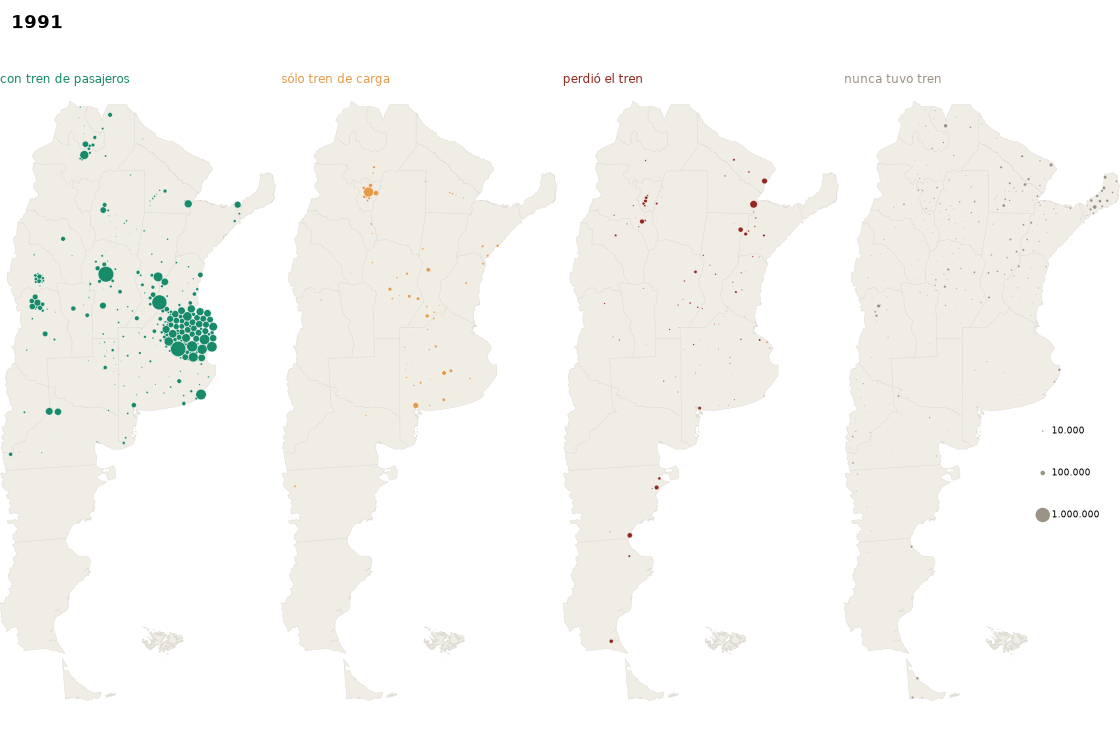

In [37]:
def separar(px, py, vx, vy, radio):
    """Empuja cada par de círculos que se pisan, en proporción al solape; el chico cede más."""
    pares = cKDTree(np.c_[px, py]).query_pairs(2 * radio.max(), output_type='ndarray')
    a, b = pares[:, 0], pares[:, 1]
    dx = px[b] - px[a]
    dy = py[b] - py[a]
    d = np.maximum(np.hypot(dx, dy), 1)
    solape = np.maximum(radio[a] + radio[b] - d, 0) / d
    w = radio[a] ** 2 / (radio[a] ** 2 + radio[b] ** 2)
    np.add.at(vx, a, -dx * solape * (1 - w))
    np.add.at(vy, a, -dy * solape * (1 - w))
    np.add.at(vx, b, dx * solape * w)
    np.add.at(vy, b, dy * solape * w)
    return (solape * d).max()

def dorling(x0, y0, radio, pasos=300, atraccion=.1, friccion=.4):
    """Acomoda los círculos para que no se pisen sin alejarse mucho de su lugar: en cada paso los
    atrae hacia su origen y separa los que se tocan, con una atracción que se apaga en `pasos` pasos."""
    px, py = x0.copy(), y0.copy()
    vx, vy = np.zeros_like(px), np.zeros_like(py)
    alpha = 1.0
    enfriamiento = 1 - .001 ** (1 / pasos)
    for _ in range(pasos):
        alpha -= alpha * enfriamiento
        vx += (x0 - px) * atraccion * alpha
        vy += (y0 - py) * atraccion * alpha
        separar(px + vx, py + vy, vx, vy, radio)
        vx *= 1 - friccion
        vy *= 1 - friccion
        px += vx
        py += vy
    # El solape que deja la simulación se deshace moviendo directo las posiciones.
    for _ in range(1000):
        if separar(px, py, px, py, radio) < 100:
            break
    return px, py

r = radios.assign(sx=radios.x * radios.pob, sy=radios.y * radios.pob)
circ = r.groupby(['censo', 'dep', 'acceso']).agg(pob=('pob', 'sum'), sx=('sx', 'sum'), sy=('sy', 'sum')).reset_index()
circ = circ[circ.pob >= MIN_CIRCULO].reset_index(drop=True)
circ['radio'] = R_MAX_CIRCULO * np.sqrt(circ.pob / circ.pob.max())
circ['x'] = circ.sx / circ.pob
circ['y'] = circ.sy / circ.pob
for (censo, tipo), grupo in circ.groupby(['censo', 'acceso']):
    px, py = dorling(grupo.x.values, grupo.y.values, grupo.radio.values)
    circ.loc[grupo.index, 'x'] = px
    circ.loc[grupo.index, 'y'] = py
print(circ.groupby('censo').size().to_string())

def radio_de(pob):
    return R_MAX_CIRCULO * np.sqrt(pob / circ.pob.max())

cuadros = []
for censo in CENSOS:
    fig, axs = paneles(censo)
    for ax, tipo in zip(axs, TIPOS):
        c = circ[(circ.censo == censo) & (circ.acceso == tipo)]
        circulos = [Circle((x, y), radio) for x, y, radio in zip(c.x, c.y, c.radio)]
        ax.add_collection(PatchCollection(circulos, facecolor=COLOR[tipo], edgecolor=FONDO, linewidths=.3))
    valores = [10_000, 100_000, 1_000_000]
    x, ys = referencia(axs[3], valores)
    axs[3].add_collection(PatchCollection([Circle((x, y), radio_de(v)) for y, v in zip(ys, valores)],
                                          facecolor=COLOR[NUNCA]))
    cuadros.append(cuadro(fig, GIF_DPI_CENSOS))
    plt.close(fig)
gif(cuadros, GIF_MS_POR_CENSO)

### Hexágonos de color y de tamaño

La gente de cada categoría junta en hexágonos de 50 km de punta a punta. En el primer gif la
población va en la intensidad del color y en el segundo en el área del hexágono, los dos en escala
logarítmica entre mil y tres millones de personas.

censo
1991    2339
2001    2383
2010    2379
2022    2364
4 cuadros · 0.3 MB


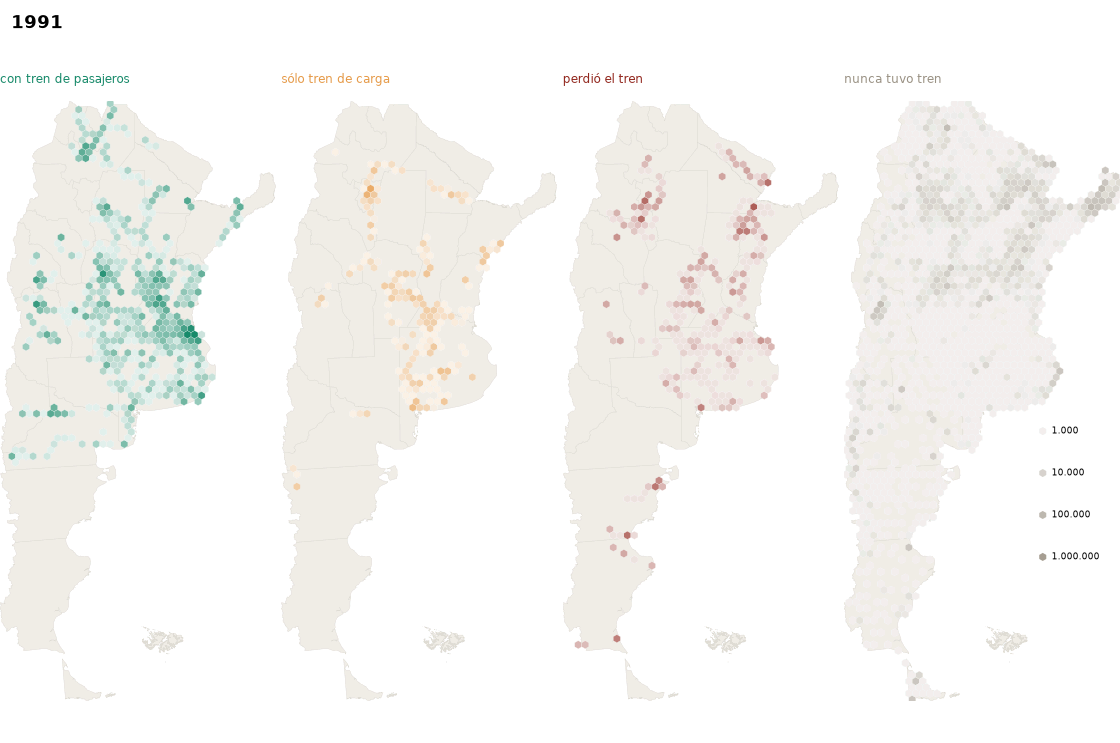

4 cuadros · 0.3 MB


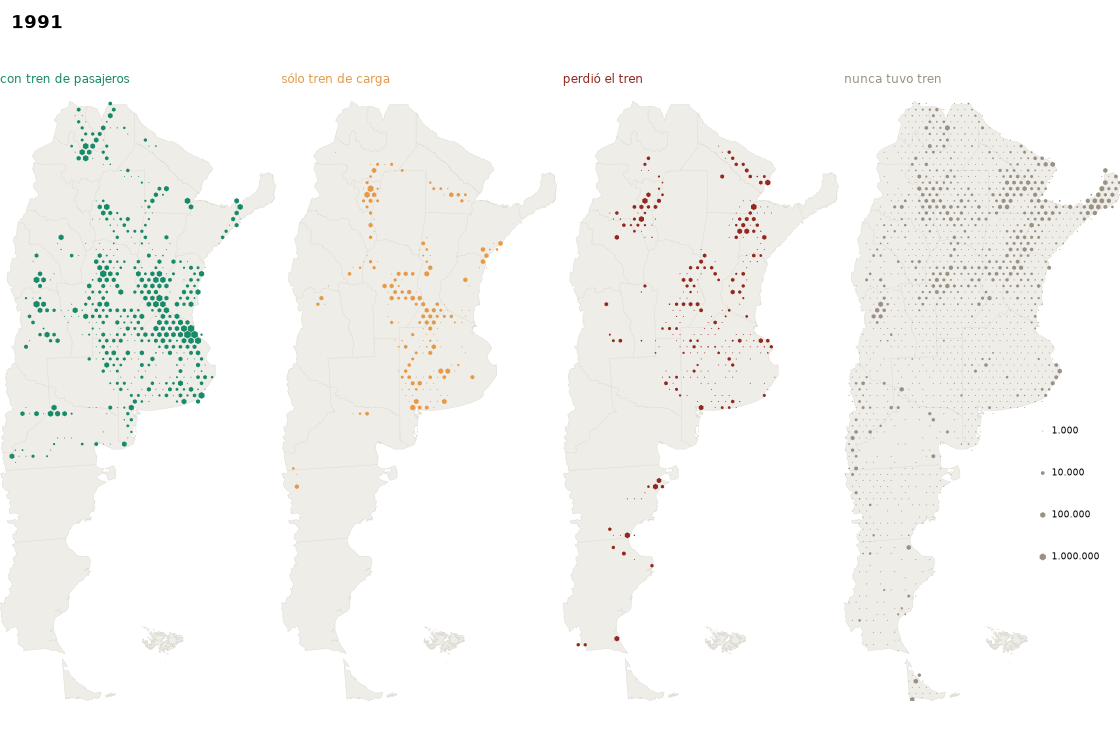

In [38]:
# Los centros de una grilla de hexágonos son dos grillas rectangulares corridas media celda.
ANCHO_HEX = np.sqrt(3) * R_HEX
ALTO_FILA = 3 * R_HEX
ANGULOS = np.radians([30, 90, 150, 210, 270, 330])
VERTICES_HEX = np.c_[np.cos(ANGULOS), np.sin(ANGULOS)] * R_HEX

def centro_hex(x, y):
    xa = np.round(x / ANCHO_HEX) * ANCHO_HEX
    ya = np.round(y / ALTO_FILA) * ALTO_FILA
    xb = (np.floor(x / ANCHO_HEX) + .5) * ANCHO_HEX
    yb = (np.floor(y / ALTO_FILA) + .5) * ALTO_FILA
    usa_a = (x - xa) ** 2 + (y - ya) ** 2 <= (x - xb) ** 2 + (y - yb) ** 2
    return np.where(usa_a, xa, xb), np.where(usa_a, ya, yb)

def hexagonos(x, y, escala):
    poligonos = []
    for cx, cy, e in zip(x, y, escala):
        poligonos.append(VERTICES_HEX * e + (cx, cy))
    return poligonos

def intensidad(pob):
    """Posición de la población en la escala logarítmica de POB_HEX, de 0 a 1."""
    desde, hasta = np.log10(POB_HEX)
    return np.clip((np.log10(pob) - desde) / (hasta - desde), 0, 1)

def tono(tipo, pob):
    fondo = np.array(to_rgb(FONDO))
    return fondo + (.12 + .88 * intensidad(pob))[:, None] * (np.array(to_rgb(COLOR[tipo])) - fondo)

def lado(pob):
    # El área sigue a la escala logarítmica; con menos de mil personas queda un punto visible.
    return .95 * np.sqrt(np.maximum(intensidad(pob), .02))

hx, hy = centro_hex(radios.x.values, radios.y.values)
hexs = radios.assign(hx=hx, hy=hy).groupby(['censo', 'acceso', 'hx', 'hy']).pob.sum().reset_index()
hexs = hexs[hexs.pob > 0]
print(hexs.groupby('censo').size().to_string())
VALORES_HEX = np.array([1e3, 1e4, 1e5, 1e6])

for por_color in (True, False):
    cuadros = []
    for censo in CENSOS:
        fig, axs = paneles(censo)
        for ax, tipo in zip(axs, TIPOS):
            h = hexs[(hexs.censo == censo) & (hexs.acceso == tipo)]
            if por_color:
                ax.add_collection(PolyCollection(hexagonos(h.hx, h.hy, np.ones(len(h))),
                                                 facecolors=tono(tipo, h.pob.values), edgecolors=FONDO, linewidths=.2))
            else:
                ax.add_collection(PolyCollection(hexagonos(h.hx, h.hy, lado(h.pob.values)),
                                                 facecolors=COLOR[tipo], linewidths=0))
        x, ys = referencia(axs[3], VALORES_HEX)
        if por_color:
            escala = hexagonos(np.full(4, x), ys, np.ones(4))
            axs[3].add_collection(PolyCollection(escala, facecolors=tono(NUNCA, VALORES_HEX)))
        else:
            escala = hexagonos(np.full(4, x), ys, lado(VALORES_HEX))
            axs[3].add_collection(PolyCollection(escala, facecolors=COLOR[NUNCA]))
        cuadros.append(cuadro(fig, GIF_DPI_CENSOS))
        plt.close(fig)
    display(gif(cuadros, GIF_MS_POR_CENSO))